# 01. 갱신을 직교화하는 optimizer — Muon

이 저장소의 prior-fitting은 기본으로 Adam을 씁니다. Muon(Jordan et al. 2024)은 가중치 행렬의 gradient(정확히는 momentum)를 그대로 쓰지 않고, 그 행렬을 **직교 행렬** 쪽으로 바꿔서 갱신합니다. TabICLv2 같은 최근 표 모델이 쓰고, 이 저장소의 v3.5 비교 실험(issue #28)에서도 Adam보다 나아서 v3.5 논문 규모 학습에 썼습니다. 구현은 `minipfn/training/muon.py`의 `MuonAdam`이고, 학습 설정은 `TrainConfig(optimizer="muon")`입니다.

다루는 흐름:

1. 직교화가 하는 일 — 특잇값을 모두 1로
2. SVD 없이 직교화하기 — Newton–Schulz 반복
3. 어느 파라미터를 Muon이 맡나
4. 작은 모델로 Adam과 견주기
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_training/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 4절은 graph SCM prior(`tabicl` 패키지)로 학습 데이터를 만들고 CPU에서 작은 모델을 학습하므로 3분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from minipfn import set_seed
from minipfn.training import muon
from minipfn.training.config import TrainConfig
from minipfn.training.losses import prior_loss
from minipfn.training.muon import MuonAdam, muon_parameters

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 직교화가 하는 일 — 특잇값을 모두 1로

가중치 행렬 $W$의 gradient $G$도 행렬입니다. 행렬은 SVD로 $G = U \Sigma V^\top$, 곧 "어느 방향($U$, $V$)으로 얼마나 크게($\Sigma$의 특잇값)"로 나눌 수 있습니다. 학습 중 gradient는 대개 몇몇 방향이 아주 크고 나머지는 작습니다. 그대로 따라가면 큰 방향으로만 움직이고 작은 방향은 거의 배우지 못합니다.

Muon은 특잇값을 버리고 방향만 남긴 $U V^\top$로 갱신합니다. 모든 특잇값이 1인 직교 행렬이라, 모든 방향을 같은 크기로 움직입니다. 특잇값이 10, 1, 0.1인 4×3 gradient를 만들어 봅니다.

In [3]:
rng = np.random.default_rng(0)
u, _ = np.linalg.qr(rng.normal(size=(4, 3)))  # 4×3, 열이 직교
v, _ = np.linalg.qr(rng.normal(size=(3, 3)))  # 3×3 직교
gradient = u @ np.diag([10.0, 1.0, 0.1]) @ v.T

u_g, s_g, vt_g = np.linalg.svd(gradient, full_matrices=False)
orthogonal = u_g @ vt_g  # Muon이 원하는 갱신: U Vᵀ
adam_like = np.sign(gradient)  # Adam의 첫 step은 원소마다 g / |g|, 곧 부호와 같다

singular = pd.DataFrame(
    {
        "gradient 그대로": np.linalg.svd(gradient, compute_uv=False),
        "U Vᵀ (Muon)": np.linalg.svd(orthogonal, compute_uv=False),
        "sign(G) (Adam 첫 step)": np.linalg.svd(adam_like, compute_uv=False),
    },
    index=["방향 1", "방향 2", "방향 3"],
)
display(singular.round(3))

,gradient 그대로,U Vᵀ (Muon),sign(G) (Adam 첫 step)
방향 1,10.0,1.0,3.464
방향 2,1.0,1.0,0.000
방향 3,0.1,1.0,0.000


직교화한 $U V^\top$은 세 방향의 크기가 모두 1입니다. gradient에서 100배 차이 나던 방향 1과 방향 3이 같은 크기로 움직입니다. Adam의 첫 step(원소마다 부호)은 특잇값이 3.464, 0, 0이라 방향 1 하나로만 움직입니다. 이 gradient는 방향 1이 아주 커서, 원소마다의 부호가 모두 방향 1의 부호로 정해지기 때문입니다. Adam은 원소마다 크기를 맞추지만 행렬의 방향은 보지 않으므로 작은 방향을 살리지 못합니다.

## 2. SVD 없이 직교화하기 — Newton–Schulz 반복

큰 행렬마다 매 step SVD를 하면 느립니다. Muon은 행렬 곱만으로 $U V^\top$에 가까이 가는 Newton–Schulz 반복을 씁니다. 먼저 $X$를 크기(Frobenius norm)로 나눠 특잇값을 1 이하로 만든 뒤, 5번 다음을 되풀이합니다.

$$X \leftarrow a X + (b\, X X^\top + c\, (X X^\top)^2)\, X, \qquad (a, b, c) = (3.4445, -4.7750, 2.0315)$$

특잇값 $\sigma$ 하나만 보면 $\sigma \leftarrow a\sigma + b\sigma^3 + c\sigma^5$입니다. 이 다항식이 0과 1 사이의 값을 빠르게 1 근처로 밀어 올리도록 계수를 골랐습니다. 반복마다 특잇값을 따라가 봅니다.

In [4]:
a, b, c = muon.NS_COEFFICIENTS
x = gradient.T.copy()  # 저장소처럼 넓은 쪽(행 ≤ 열)으로 돌려서 계산한다
x = x / np.linalg.norm(x)  # Frobenius norm으로 나누면 특잇값이 모두 1 이하
steps = {"시작 (norm으로 나눔)": np.linalg.svd(x, compute_uv=False)}
for k in range(muon.NS_STEPS):
    gram = x @ x.T
    x = a * x + (b * gram + c * gram @ gram) @ x
    steps[f"{k + 1}번째"] = np.linalg.svd(x, compute_uv=False)
ns_table = pd.DataFrame(steps, index=["방향 1", "방향 2", "방향 3"]).T
display(ns_table.round(3))

repo = muon._newton_schulz(torch.tensor(gradient, dtype=torch.float32))  # 저장소 함수 (bf16)
print("저장소 _newton_schulz 결과의 특잇값:", torch.linalg.svdvals(repo.float()).numpy().round(3))
print("U Vᵀ와의 차이 (원소 최대):", np.abs(repo.float().numpy() - orthogonal).max().round(3))

,방향 1,방향 2,방향 3
시작 (norm으로 나눔),0.995,0.099,0.010
1번째,0.705,0.338,0.034
2번째,1.109,0.989,0.118
3번째,0.715,0.710,0.398
4번째,1.103,1.097,1.090
5번째,0.709,0.702,0.697


저장소 _newton_schulz 결과의 특잇값: [0.718 0.712 0.69 ]
U Vᵀ와의 차이 (원소 최대): 0.287


norm으로 나누고 나면 특잇값이 0.995, 0.099, 0.010입니다. 반복할 때마다 작은 값이 빠르게 커져서, 5번 뒤에는 세 방향이 모두 0.7쯤이 됩니다. 정확히 1로 가지 않고 0.7~1.1 사이를 오가는 것은 계수를 일부러 그렇게 골랐기 때문입니다. 1에 정확히 맞추기보다 작은 특잇값을 적은 반복으로 빨리 키우는 쪽을 택한 것입니다. 목적은 방향 사이의 크기 차이(10 : 1 : 0.1)를 없애는 것이라 이 정도면 충분합니다. 저장소 함수도 bf16으로 같은 계산을 해서 특잇값이 0.69~0.72로 나옵니다.

## 3. 어느 파라미터를 Muon이 맡나

직교화는 행렬에만 뜻이 있습니다. 그래서 `MuonAdam`은 파라미터를 둘로 나눕니다(`muon_parameters`).

- **Muon**: 반복되는 Transformer 블록(`model.repeated_blocks()`) 안의 2차원 가중치 행렬. q·k·v를 한 행렬로 묶은 `qkv`는 셋으로 나눠 따로 직교화합니다.
- **Adam**: 나머지 전부. 입력 encoder, embedding, bias, LayerNorm, 출력층입니다.

두 묶음은 같은 학습률을 씁니다. Muon 갱신의 크기를 AdamW 갱신의 크기(RMS)에 맞추는 보정($0.2 \sqrt{\max(\text{행}, \text{열})}$, Moonshot)을 곱하기 때문에, Adam에 쓰던 학습률·warmup·cosine을 그대로 씁니다. 4절에서 학습할 작은 모델(v2 구조, 폭 64, 층 3개)로 나눠 봅니다.

In [5]:
config = TrainConfig(
    task="classification",
    emsize=64,  # 셀 토큰 폭 (v2는 192)
    nlayers=3,  # 층 수 (v2는 12)
    nhead=4,
    max_train_rows=128,  # 학습 행 상한
    n_eval_rows=64,  # 검증(query) 행
    max_features=8,
    micro_batch=16,
    val_batch=16,
)
model = config.build_model()
muon_params, adam_params = muon_parameters(model)
names = {id(p): n for n, p in model.named_parameters()}
rows = [
    {"파라미터": names[id(p)], "모양": tuple(p.shape), "맡는 쪽": f"Muon (조각 {s})"}
    for p, s in muon_params
][:4]
rows += [
    {"파라미터": names[id(p)], "모양": tuple(p.shape), "맡는 쪽": "Adam"} for p in adam_params
][:4]
display(pd.DataFrame(rows))
n_muon = sum(p.numel() for p, _ in muon_params)
n_adam = sum(p.numel() for p in adam_params)
print(f"Muon: 행렬 {len(muon_params)}개, {n_muon:,}개 숫자")
print(f"Adam: {len(adam_params)}개, {n_adam:,}개 숫자")

,파라미터,모양,맡는 쪽
0,layers.0.feature_attention.qkv.weight,"(192, 64)",Muon (조각 3)
1,layers.0.feature_attention.out.weight,"(64, 64)",Muon (조각 1)
2,layers.0.sample_attention.qkv.weight,"(192, 64)",Muon (조각 3)
3,layers.0.sample_attention.out.weight,"(64, 64)",Muon (조각 1)
4,feature_embedder.weight,"(64, 4)",Adam
5,feature_embedder.bias,"(64,)",Adam
6,target_embedder.weight,"(64, 2)",Adam
7,target_embedder.bias,"(64,)",Adam


Muon: 행렬 18개, 196,608개 숫자
Adam: 10개, 20,810개 숫자


숫자로는 90%가 Muon 쪽입니다. 블록 안의 attention(`qkv`, `out`)과 MLP 행렬이 모델의 대부분이기 때문입니다. `qkv` 행렬(192 × 64)은 q·k·v 세 조각(각 64 × 64)으로 나눠 직교화합니다. feature·target embedder처럼 입력을 펴는 층과 bias, 출력층은 Adam이 맡습니다.

## 4. 작은 모델로 Adam과 견주기

graph SCM prior(이 저장소가 v2부터 쓰는 TabICL prior)에서 분류 데이터셋 batch 60개(데이터셋 960개)를 미리 뽑아 두고, 같은 순서로 두 optimizer에 줍니다. 모델 초기값도 같습니다. 300 step을 학습하며 50 step마다 따로 뽑아 둔 검증 batch 6개의 손실(cross-entropy)을 잽니다. 학습률은 30 step warmup 뒤 cosine으로 줄입니다. Muon은 학습률에 따라 결과가 달라질 수 있어 학습률 세 개를 둘 다에 써 봅니다.

In [6]:
start = time.perf_counter()
train_prior = config.make_prior(0)
train_batches = [train_prior.sample_batch(config.micro_batch) for _ in range(60)]
val_prior = config.make_prior(10_000_000)  # 학습과 겹치지 않는 seed
val_batches = [val_prior.sample_batch(config.val_batch) for _ in range(6)]
first = train_batches[0]
print(f"prior에서 batch 66개: {time.perf_counter() - start:.0f}초")
print(f"batch 하나: x {tuple(first.x.shape)} (데이터셋, 행, feature), 학습 행 {first.n_train}개")

prior에서 batch 66개: 21초
batch 하나: x (16, 173, 6) (데이터셋, 행, feature), 학습 행 109개


In [7]:
STEPS, WARMUP, EVAL_EVERY = 300, 30, 50


def batch_loss(model, batch):
    logits = model(batch.x, batch.y[:, : batch.n_train])  # 학습 행의 정답만 넣는다
    return prior_loss(logits, batch.y[:, batch.n_train :], "classification", None)


def validation_loss(model):
    model.eval()
    with torch.no_grad():
        loss = np.mean([batch_loss(model, b).item() for b in val_batches])
    model.train()
    return loss


def schedule(step):
    warmup = min(1.0, (step + 1) / WARMUP)
    cosine = 0.5 * (1 + math.cos(math.pi * step / STEPS))
    return warmup * cosine


def train(optimizer_name, lr):
    torch.manual_seed(0)  # 모델 초기값을 같게
    model = config.build_model()
    if optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = MuonAdam(model, lr=lr)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)
    curve = [(0, validation_loss(model))]
    start = time.perf_counter()
    for step in range(STEPS):
        loss = batch_loss(model, train_batches[step % len(train_batches)])
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        if (step + 1) % EVAL_EVERY == 0:
            curve.append((step + 1, validation_loss(model)))
    return curve, time.perf_counter() - start


curves, summary = {}, []
for lr in [1e-3, 3e-3, 1e-2]:
    for name in ["adam", "muon"]:
        curve, seconds = train(name, lr)
        curves[(name, lr)] = curve
        summary.append(
            {
                "optimizer": name,
                "학습률": lr,
                "마지막 검증 손실": curve[-1][1],
                "가장 낮은 검증 손실": min(v for _, v in curve),
                "학습 초": seconds,
            }
        )
summary = pd.DataFrame(summary).set_index(["학습률", "optimizer"])
display(summary.round(4))

마지막 검증 손실  가장 낮은 검증 손실     학습 초
학습률   optimizer                                 
0.001 adam          1.5161       1.5161  14.0079
      muon          1.5835       1.5835  21.6525
0.003 adam          1.4735       1.4735  14.0936
      muon          1.4390       1.4390  21.7848
0.010 adam          1.5756       1.5756  13.5453
      muon          1.3226       1.3226  21.7379

학습률마다 이기는 쪽이 다릅니다. 1e-3에서는 Adam이 낮고(1.516 대 1.584), 3e-3에서는 Muon이 조금 낮고(1.439 대 1.474), 1e-2에서는 Muon이 크게 낮습니다(1.323 대 1.576). 각자 가장 좋은 학습률끼리 견줘도 Muon 1e-2(1.323)가 Adam 3e-3(1.474)보다 낮습니다. 학습 시간은 CPU에서 Muon이 1.5배쯤 깁니다. Newton–Schulz의 행렬 곱 때문입니다.

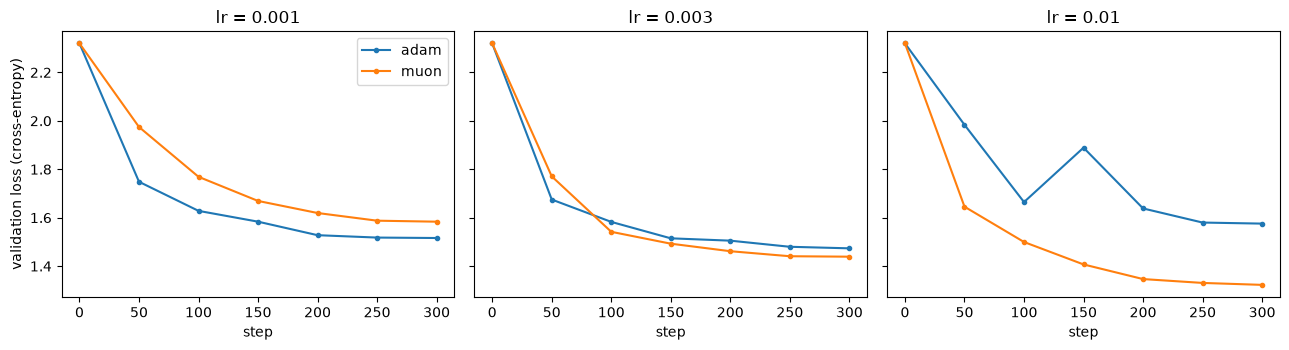

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, lr in zip(axes, [1e-3, 3e-3, 1e-2], strict=True):
    for name in ["adam", "muon"]:
        steps, losses = zip(*curves[(name, lr)], strict=True)
        ax.plot(steps, losses, marker="o", ms=3, label=name)
    ax.set_title(f"lr = {lr:g}")
    ax.set_xlabel("step")
axes[0].set_ylabel("validation loss (cross-entropy)")
axes[0].legend()
plt.tight_layout()
plt.show()

1e-2에서 Adam은 150 step 근처에서 손실이 다시 튀고 그 뒤로도 회복이 느립니다. Muon은 같은 학습률에서 매끄럽게 내려갑니다. Muon 갱신의 크기는 직교화로 정해지므로, gradient가 갑자기 커져도 갱신이 함께 커지지 않습니다. 그래서 더 큰 학습률을 견딥니다. 다만 이 toy는 300 step, 숫자 22만 개짜리 모델이라 실제 규모의 학습과는 다릅니다.

## 5. 정리

| | Adam | Muon (`MuonAdam`) |
|---|---|---|
| 갱신 | 원소마다 gradient를 제곱 평균의 제곱근으로 나눔 | 행렬마다 momentum을 직교화 ($U V^\top$, Newton–Schulz 5번) |
| 맡는 파라미터 | 전부 | 블록 안의 가중치 행렬 (나머지는 Adam) |
| 학습률 | 기준 lr | 같은 기준 lr ($0.2\sqrt{\max(A, B)}$ 보정) |
| step 비용 | 기준 | Newton–Schulz 행렬 곱만큼 더 (GPU에서는 작고, 여러 GPU면 나눠 계산: `muon_distributed`) |

- 직교화는 gradient의 큰 방향과 작은 방향을 같은 크기로 움직입니다(1절). Adam의 부호 갱신은 원소마다 크기를 맞출 뿐이라 방향의 크기 차이가 남습니다.
- toy 하나로는 어느 optimizer가 나은지 정할 수 없고, 학습률에 따라 결론이 바뀝니다(4절). 이 저장소는 v3.5 medium 규모에서 두 optimizer를 같은 설정으로 견줘 Muon을 골랐습니다(issue #28).
- 학습 설정: `TrainConfig(optimizer="muon", muon_weight_decay=0.0, muon_distributed="off")`.